# 07d · Ranking final en dos etapas: los 6 experimentos y el contraste de H1

Etapa 7, paso d (local, sin Colab). Junta el DeepFM (paso c) con los modelos de la fase 2 (paso b) sobre los candidatos de cada usuario (paso a).

**Ranking (revisión §12.4):** el DeepFM elige el **top 25 %** de los candidatos de cada usuario (25 de 100 en test) y la fase 2 lo reordena con

`score = α · pct(DeepFM) + (1 − α) · [β · pct(TTMn) + (1 − β) · pct(DLMn)]`

donde `pct` es el rango percentil dentro del usuario. **α y β se eligen en valid** (NDCG@5) para cada experimento, con α ∈ {0; 0,1; …; 1} y β ∈ {0; 0,5; 1}. α = 1 es el DeepFM solo, así que ningún experimento puede quedar peor que el 1 en valid. Se usa un α global por experimento y no uno por usuario: con 50 candidatos de valid por usuario, un α propio se sobreajusta.

| Exp. | Fase 2 |
|---|---|
| 1 | ninguna (DeepFM solo) |
| 2 | XGBoost |
| 3 | Random Forest |
| **4** | **Red GFS, Opción A** |
| 5 | MLP de igual tamaño |
| 6 | GFS con conexiones barajadas |
| Anexo | GFS, Opción B (pesos fijos) |

Cada semilla del DeepFM se combina con la misma semilla de cada red (los árboles tienen una sola). **H1:** el experimento 4 obtiene un NDCG@5 igual o mayor que los controles 5 y 6 (prueba de Wilcoxon pareada por usuario, §12.6).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr, wilcoxon

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encontró data/raw. Abre el notebook dentro del repositorio.")
sys.path.insert(0, str(ROOT / "src"))

from modelo_fly.ranking import dos_etapas, matrices, metricas_rapidas

PROC = ROOT / "data" / "processed" / "hito3"
RES = ROOT / "results" / "hito3" / "ranking"
RES.mkdir(parents=True, exist_ok=True)
SEMILLAS = [0, 1, 2]
TOP = 0.25
ALFAS = np.round(np.arange(0, 1.01, 0.1), 1)
BETAS = [0.0, 0.5, 1.0]
EXPERIMENTOS = {"1": None, "2": "xgboost", "3": "random_forest", "4": "gfs_a", "5": "mlp",
                "6": "gfs_barajada", "anexo": "gfs_b"}
NOMBRE = {"1": "DeepFM solo", "2": "+ XGBoost", "3": "+ Random Forest", "4": "+ GFS (A)", "5": "+ MLP",
          "6": "+ GFS barajada", "anexo": "+ GFS (B, fijos)"}

cand = pd.read_csv(PROC / "candidatos.csv")
dfm = pd.read_csv(PROC / "deepfm_pred_candidatos.csv.gz")
f2 = pd.read_csv(PROC / "fase2_pred_usuarios.csv.gz")
usuarios = pd.read_csv(PROC / "usuarios.csv")
cand = (cand.merge(dfm.drop(columns="particion"), on=["user_id", "outfit_id"], how="left", validate="one_to_one")
        .merge(f2, on="outfit_id", how="left", validate="many_to_one"))
assert not cand.filter(regex="deepfm|_ttmn|_dlmn").isna().any().any(), "Faltan puntajes"
cand = cand.sort_values(["particion", "user_id", "outfit_id"]).reset_index(drop=True)
print("Candidatos:", cand.groupby("particion").size().to_dict(), "| columnas de puntaje:",
      len(cand.filter(regex="deepfm|_ttmn|_dlmn").columns))

Candidatos: {'test': 35000, 'valid': 17500} | columnas de puntaje: 31


## 1. Elección de α y β en valid

In [2]:
def columnas(exp, s):
    m = EXPERIMENTOS[exp]
    sf = 0 if m in ("xgboost", "random_forest") else s
    return f"deepfm_s{s}", (f"{m}_s{sf}_ttmn" if m else None), (f"{m}_s{sf}_dlmn" if m else None)

def puntaje(d, exp, s, alfa, beta):
    c_dfm, c_t, c_d = columnas(exp, s)
    usuarios_, Y, P = matrices(d, c_dfm)
    if EXPERIMENTOS[exp] is None:
        return usuarios_, Y, P
    T = matrices(d, c_t)[2]
    D = matrices(d, c_d)[2]
    return usuarios_, Y, dos_etapas(P, T, D, alfa, beta, top=int(TOP * P.shape[1]))

va = cand[cand["particion"] == "valid"]
eleccion = []
for exp in EXPERIMENTOS:
    for s in SEMILLAS:
        if EXPERIMENTOS[exp] is None:
            eleccion.append({"experimento": exp, "semilla": s, "alfa": 1.0, "beta": np.nan,
                             "NDCG@5_valid": np.nanmean(metricas_rapidas(*puntaje(va, exp, s, 1, 0)[1:])["NDCG@5"])})
            continue
        mejor = max(((a, b) for a in ALFAS for b in BETAS),
                    key=lambda ab: (np.nanmean(metricas_rapidas(*puntaje(va, exp, s, *ab)[1:])["NDCG@5"]), ab[0]))
        eleccion.append({"experimento": exp, "semilla": s, "alfa": mejor[0], "beta": mejor[1],
                         "NDCG@5_valid": np.nanmean(metricas_rapidas(*puntaje(va, exp, s, *mejor)[1:])["NDCG@5"])})
eleccion = pd.DataFrame(eleccion)
display(eleccion.pivot(index="experimento", columns="semilla", values=["alfa", "beta", "NDCG@5_valid"]).round(3))

alfa           beta           NDCG@5_valid              
semilla        0    1    2    0    1    2            0      1      2
experimento                                                         
1            1.0  1.0  1.0  NaN  NaN  NaN        0.723  0.708  0.694
2            0.8  0.8  0.5  1.0  1.0  1.0        0.737  0.724  0.713
3            0.6  0.8  0.4  0.5  1.0  0.5        0.737  0.720  0.713
4            0.8  0.9  0.8  1.0  1.0  0.5        0.727  0.712  0.698
5            0.7  0.8  0.6  0.5  1.0  1.0        0.740  0.721  0.717
6            0.8  0.9  0.8  0.5  0.0  0.5        0.731  0.712  0.699
anexo        0.9  0.9  0.8  1.0  1.0  0.5        0.724  0.716  0.697

## 2. Resultados en test

Media por usuario de cada métrica; ± es la desviación estándar entre las 3 semillas. Las pruebas usan, por usuario, el promedio de las 3 semillas.

In [3]:
te = cand[cand["particion"] == "test"]
por_usuario, filas = [], []
for r in eleccion.itertuples():
    u, Y, S = puntaje(te, r.experimento, r.semilla, r.alfa, 0 if np.isnan(r.beta) else r.beta)
    m = metricas_rapidas(Y, S)
    filas.append({"experimento": r.experimento, "semilla": r.semilla, **{k: np.nanmean(v) for k, v in m.items()}})
    por_usuario.append(pd.DataFrame({"user_id": u, "experimento": r.experimento, "semilla": r.semilla, **m}))
for nombre, col in [("azar", None), ("techo", "p_real")]:
    if col is None:
        te = te.assign(_azar=np.random.default_rng(0).random(len(te)))
        col = "_azar"
    m = metricas_rapidas(*matrices(te, col)[1:])
    filas.append({"experimento": nombre, "semilla": 0, **{k: np.nanmean(v) for k, v in m.items()}})
res = pd.DataFrame(filas)
por_usuario = pd.concat(por_usuario, ignore_index=True)
METRICAS = ["NDCG@5", "NDCG@10", "Recall@5", "Recall@10", "HitRate@5"]
tabla = res.groupby("experimento", sort=False)[METRICAS].agg(["mean", "std"]).round(3)
tabla.insert(0, ("modelo", ""), [NOMBRE.get(e, e) for e in tabla.index])
display(tabla)

modelo NDCG@5        NDCG@10        Recall@5         \
                                mean    std    mean    std     mean    std   
experimento                                                                  
1                 DeepFM solo  0.750  0.014   0.734  0.013    0.741  0.013   
2                   + XGBoost  0.758  0.006   0.740  0.009    0.752  0.006   
3             + Random Forest  0.767  0.009   0.742  0.011    0.757  0.010   
4                   + GFS (A)  0.744  0.009   0.726  0.011    0.738  0.009   
5                       + MLP  0.744  0.015   0.731  0.018    0.739  0.011   
6              + GFS barajada  0.748  0.016   0.732  0.017    0.742  0.015   
anexo        + GFS (B, fijos)  0.751  0.012   0.730  0.013    0.743  0.010   
azar                     azar  0.492    NaN   0.493    NaN    0.496    NaN   
techo                   techo  0.919    NaN   0.905    NaN    0.920    NaN   

            Recall@10        HitRate@5         
                 mean    std      mean    std  
experimento                                    
1               0.721  0.012     0.995  0.002  
2               0.729  0.010     0.998  0.002  
3               0.726  0.011     0.997  0.003  
4               0.714  0.012     0.993  0.002  
5               0.722  0.017     0.995  0.003  
6               0.721  0.017     0.996  0.002  
anexo           0.717  0.014     0.994  0.003  
azar            0.495    NaN     0.971    NaN  
techo           0.900    NaN     1.000    NaN

## 3. Contraste de H1 y comparaciones

Wilcoxon de rangos con signo, pareado por usuario, sobre NDCG@5 (promedio de las 3 semillas). Intervalo de confianza del 95 % de la diferencia de medias por bootstrap de usuarios (5 000 remuestreos). Se corrige por comparaciones múltiples con Holm.

In [4]:
pu = por_usuario.groupby(["experimento", "user_id"])["NDCG@5"].mean().unstack(0)
COMPARACIONES = [("4", "5", "H1: GFS vs MLP de igual tamaño"), ("4", "6", "H1: GFS vs GFS barajada"),
                 ("4", "1", "¿La GFS aporta sobre el DeepFM solo?"), ("2", "1", "¿XGBoost aporta sobre el DeepFM solo?"),
                 ("3", "1", "¿RF aporta sobre el DeepFM solo?"), ("5", "1", "¿El MLP aporta sobre el DeepFM solo?"),
                 ("4", "2", "GFS vs XGBoost"), ("4", "anexo", "Opción A vs Opción B")]
rng = np.random.default_rng(2026)
filas = []
for a, b, pregunta in COMPARACIONES:
    d = (pu[a] - pu[b]).dropna().to_numpy()
    boot = [rng.choice(d, len(d)).mean() for _ in range(5000)]
    p = wilcoxon(d, zero_method="zsplit").pvalue if np.any(d != 0) else 1.0
    filas.append({"comparacion": f"{a} vs {b}", "pregunta": pregunta, "dif_media_NDCG@5": d.mean(),
                  "IC95_inf": np.percentile(boot, 2.5), "IC95_sup": np.percentile(boot, 97.5),
                  "gana_a_%": 100 * (d > 0).mean(), "pierde_a_%": 100 * (d < 0).mean(), "p_wilcoxon": p})
pruebas = pd.DataFrame(filas)
orden_p = np.argsort(pruebas["p_wilcoxon"].to_numpy())
holm = np.empty(len(pruebas))
acum = 0
for i, j in enumerate(orden_p):
    acum = max(acum, min(1, (len(pruebas) - i) * pruebas.loc[j, "p_wilcoxon"]))
    holm[j] = acum
pruebas["p_holm"] = holm
display(pruebas.round(4))

,comparacion,pregunta,dif_media_NDCG@5,IC95_inf,IC95_sup,gana_a_%,pierde_a_%,p_wilcoxon,p_holm
0,4 vs 5,H1: GFS vs MLP de igual tamaño,-0.0003,-0.0127,0.0122,47.4286,47.4286,0.9823,1.0000
1,4 vs 6,H1: GFS vs GFS barajada,-0.0046,-0.0143,0.0055,43.1429,46.5714,0.4755,1.0000
2,4 vs 1,¿La GFS aporta sobre el DeepFM solo?,-0.0065,-0.0181,0.0056,43.4286,48.2857,0.1576,0.7882
3,2 vs 1,¿XGBoost aporta sobre el DeepFM solo?,0.0071,-0.0118,0.0251,48.2857,45.1429,0.5783,1.0000
4,3 vs 1,¿RF aporta sobre el DeepFM solo?,0.0166,0.0005,0.0326,52.8571,40.2857,0.0360,0.2880
5,5 vs 1,¿El MLP aporta sobre el DeepFM solo?,-0.0062,-0.0218,0.0097,45.1429,49.7143,0.3573,1.0000
6,4 vs 2,GFS vs XGBoost,-0.0136,-0.0295,0.0029,42.5714,52.0000,0.0902,0.5412
7,4 vs anexo,Opción A vs Opción B,-0.0070,-0.0142,0.0005,38.2857,48.2857,0.0455,0.3184


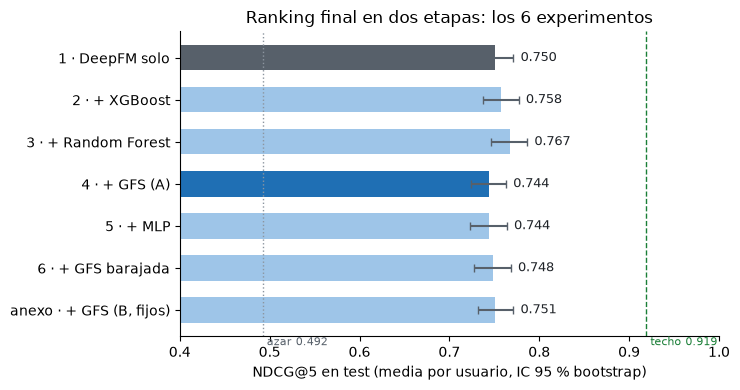

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4))
orden = ["1", "2", "3", "4", "5", "6", "anexo"]
medias = pu[orden].mean()
ic = np.array([[np.percentile([rng.choice(pu[e].dropna().to_numpy(), len(pu)).mean() for _ in range(2000)], q)
                for q in (2.5, 97.5)] for e in orden])
pos = np.arange(len(orden))[::-1]
colores = ["#57606a"] + ["#9ec5e8"] * 2 + ["#1f6fb4"] + ["#9ec5e8"] * 3
ax.barh(pos, medias, xerr=[medias - ic[:, 0], ic[:, 1] - medias], color=colores, height=0.6,
        error_kw={"ecolor": "#57606a", "capsize": 3})
ax.set_yticks(pos, [f"{e} · {NOMBRE[e]}" for e in orden])
for y_, v, sup in zip(pos, medias, ic[:, 1]):
    ax.text(sup + 0.008, y_, f"{v:.3f}", va="center", fontsize=9, color="#1f2328")
techo = res.loc[res["experimento"] == "techo", "NDCG@5"].iloc[0]
azar = res.loc[res["experimento"] == "azar", "NDCG@5"].iloc[0]
ax.axvline(techo, color="#1a7f37", ls="--", lw=1)
ax.axvline(azar, color="#8c959f", ls=":", lw=1)
ax.text(techo, -0.9, f" techo {techo:.3f}", color="#1a7f37", fontsize=8, va="bottom")
ax.text(azar, -0.9, f" azar {azar:.3f}", color="#57606a", fontsize=8, va="bottom")
ax.set_xlim(0.4, 1.0)
ax.set_xlabel("NDCG@5 en test (media por usuario, IC 95 % bootstrap)")
ax.set_title("Ranking final en dos etapas: los 6 experimentos")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(RES / "fig_ranking_experimentos.png", dpi=150)
plt.show()

## 4. Análisis de errores

- **Por grupo de usuario** (mixto vs. transferencia) y **por arquetipo** y **clima**.
- **¿El DeepFM recupera el gusto programado?** Correlación de Spearman, por usuario, entre la probabilidad del DeepFM y la probabilidad real de la simulación en sus 100 candidatos de test.

In [6]:
info = usuarios.set_index("user_id")[["grupo", "arquetipo", "clima", "estilo_fav"]]
mejor_exp = max(["2", "3", "4", "5", "6"], key=lambda e: pu[e].mean())
comp = pu[["1", "4", mejor_exp]].join(info)
for col in ["grupo", "arquetipo", "clima"]:
    display(comp.groupby(col)[["1", "4", mejor_exp]].agg(["mean", "count"]).round(3)
            .rename(columns={"1": "DeepFM solo", "4": "+ GFS", mejor_exp: f"+ mejor ({NOMBRE[mejor_exp]})"}))

rec = []
for u, g in te.groupby("user_id"):
    rec.append({"user_id": u, "spearman_deepfm": spearmanr(g[[f"deepfm_s{s}" for s in SEMILLAS]].mean(axis=1), g["p_real"])[0],
                "spearman_ttmn_gfs": spearmanr(g[[f"gfs_a_s{s}_ttmn" for s in SEMILLAS]].mean(axis=1), g["p_real"])[0],
                "spearman_ttmn_xgb": spearmanr(g["xgboost_s0_ttmn"], g["p_real"])[0]})
rec = pd.DataFrame(rec).set_index("user_id").join(info)
print("Spearman medio con la probabilidad real:", rec[["spearman_deepfm", "spearman_ttmn_gfs", "spearman_ttmn_xgb"]].mean().round(3).to_dict())
display(rec.groupby("arquetipo")[["spearman_deepfm", "spearman_ttmn_gfs", "spearman_ttmn_xgb"]].mean().round(3))

DeepFM solo        + GFS       + mejor (+ Random Forest)      
                     mean count   mean count                      mean count
grupo                                                                       
mixto               0.750   300  0.741   300                     0.765   300
transferencia       0.753    50  0.761    50                     0.781    50

DeepFM solo        + GFS       + mejor (+ Random Forest)      
                   mean count   mean count                      mean count
arquetipo                                                                 
atrevido          0.601    61  0.604    61                     0.641    61
clasico           0.789    80  0.787    80                     0.815    80
deportivo         0.739    71  0.736    71                     0.762    71
minimalista       0.835    76  0.820    76                     0.820    76
vintage           0.757    62  0.743    62                     0.769    62

DeepFM solo        + GFS       + mejor (+ Random Forest)      
                mean count   mean count                      mean count
clima                                                                  
calido         0.792    61  0.789    61                     0.803    61
frio           0.736    73  0.716    73                     0.749    73
templado       0.744   216  0.741   216                     0.763   216

Spearman medio con la probabilidad real: {'spearman_deepfm': 0.502, 'spearman_ttmn_gfs': 0.192, 'spearman_ttmn_xgb': 0.251}


,spearman_deepfm,spearman_ttmn_gfs,spearman_ttmn_xgb
arquetipo,,,
atrevido,0.136,0.152,0.235
clasico,0.656,0.254,0.278
deportivo,0.491,0.135,0.222
minimalista,0.663,0.183,0.245
vintage,0.481,0.229,0.269


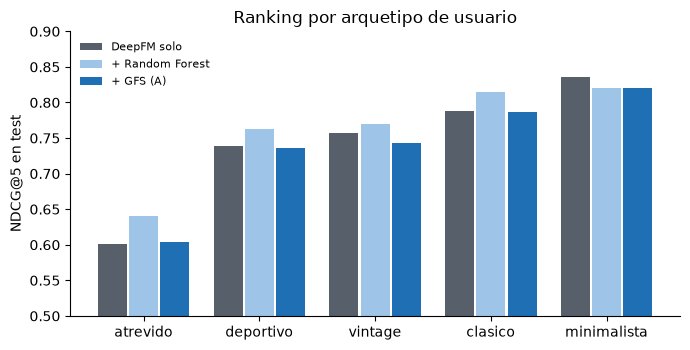

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
arq = comp.groupby("arquetipo")[["1", mejor_exp, "4"]].mean().sort_values("1")
x = np.arange(len(arq))
for i, (col, color, etiqueta) in enumerate([("1", "#57606a", "DeepFM solo"), (mejor_exp, "#9ec5e8", NOMBRE[mejor_exp]),
                                            ("4", "#1f6fb4", NOMBRE["4"])]):
    ax.bar(x + (i - 1) * 0.27, arq[col], width=0.25, color=color, label=etiqueta)
ax.set_xticks(x, arq.index)
ax.set_ylim(0.5, 0.9)
ax.set_ylabel("NDCG@5 en test")
ax.set_title("Ranking por arquetipo de usuario")
ax.legend(fontsize=8, frameon=False)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(RES / "fig_ranking_arquetipos.png", dpi=150)
plt.show()

## 5. Salidas

In [8]:
tabla.to_csv(RES / "ranking_metricas.csv")
res.round(5).to_csv(RES / "ranking_metricas_por_semilla.csv", index=False)
eleccion.round(4).to_csv(RES / "ranking_alfa_beta.csv", index=False)
pruebas.round(6).to_csv(RES / "ranking_pruebas.csv", index=False)
por_usuario.round(5).to_csv(RES / "ranking_por_usuario.csv.gz", index=False)
rec.round(4).to_csv(RES / "ranking_recuperacion_gusto.csv")
print("Guardado en", RES.relative_to(ROOT), sorted(p.name for p in RES.iterdir()))

Guardado en results\hito3\ranking ['fig_ranking_arquetipos.png', 'fig_ranking_experimentos.png', 'ranking_alfa_beta.csv', 'ranking_metricas.csv', 'ranking_metricas_por_semilla.csv', 'ranking_por_usuario.csv.gz', 'ranking_pruebas.csv', 'ranking_recuperacion_gusto.csv']
